In [44]:
import numpy as np
import matplotlib.pyplot as plt
import OpenGL as gl
import glfw

In [59]:
cube_vertices = np.array([
                            [ 1,  1,  1],
                            [-1,  1,  1],
                            [ 1, -1,  1],
                            [-1, -1,  1],
                            [ 1,  1, -1],
                            [-1,  1, -1],
                            [ 1, -1, -1],
                            [-1, -1, -1],
])
print(cube_vertices)

[[ 1  1  1]
 [-1  1  1]
 [ 1 -1  1]
 [-1 -1  1]
 [ 1  1 -1]
 [-1  1 -1]
 [ 1 -1 -1]
 [-1 -1 -1]]


In [60]:
cube_edges = np.array([
    [0, 1],[2, 3],[4, 5],[6, 7],
    [0, 2],[1, 3],[4, 6],[5, 7],
    [0, 4],[2, 6],[1, 5],[3, 7],
])
print(cube_edges)

[[0 1]
 [2 3]
 [4 5]
 [6 7]
 [0 2]
 [1 3]
 [4 6]
 [5 7]
 [0 4]
 [2 6]
 [1 5]
 [3 7]]


In [61]:
camera_pos = np.array([4, 2, 4]) 

def project_vertices(V, camera_pos):
    cam_vertices = V-camera_pos # cam translate
    screen_coordinates = [] # screen projection

    for vertex in cam_vertices:
        x, y, z = vertex
        u = -x/z
        v = -y/z
        screen_coordinates.append([u, v])

    return np.array(screen_coordinates)
    
screen_coordinates = project_vertices(cube_vertices, c)
print(f"Screen Coordinates: {screen_coordinates}")

Screen Coordinates: [[-1.         -0.33333333]
 [-1.66666667 -0.33333333]
 [-1.         -1.        ]
 [-1.66666667 -1.        ]
 [-0.6        -0.2       ]
 [-1.         -0.2       ]
 [-0.6        -0.6       ]
 [-1.         -0.6       ]]


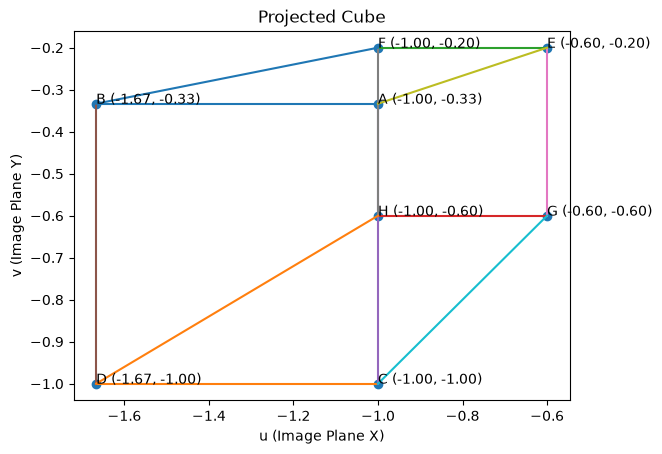

In [64]:
plt.scatter(screen_coordinates[:, 0], screen_coordinates[:, 1])

for edge in cube_edges:
    i, j = edge

    plt.plot(
        [screen_coordinates[i, 0], screen_coordinates[j, 0]],
        [screen_coordinates[i, 1], screen_coordinates[j, 1]]
    )

for i, label in enumerate(labels):
    u, v = screen_coordinates[i]
    plt.text(u, v, f"{label} ({u:.2f}, {v:.2f})")



plt.xlabel("u (Image Plane X)")
plt.ylabel("v (Image Plane Y)")
plt.title("Projected Cube")
plt.show()